In [23]:
from utils import load_data, translate_generated_sequence
import torch
from torch import nn
import torch.nn.functional as F
import torch.optim as optim
import torch.nn.init as init
from torch.nn.parameter import Parameter
from sklearn.metrics import accuracy_score

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from torch.utils.data import DataLoader, TensorDataset

# Loading data for training the generative model
data_train, train_loader, X_train, y_train = load_data(
    data_dir_path="../data", 
    type="train", 
    task="generative"
)

# Loading data for validation of the generative model
data_val, val_loader, X_val, y_val = load_data(
    data_dir_path="../data", 
    type="val", 
    task="generative"
)

# train data, task: generative
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020, 129])
# val data, task: generative
 Tokens shape: torch.Size([2001, 129])
 Labels (shape): torch.Size([2001, 129])


# Data preparation

Prepares substrings of length 3 from training and validation data, and the corresponding y labels that represent the next character in the sequence

In [24]:
def prepare_data(X, y):
    # Get all substrings of length 3 from the data
    X_substrings = []
    for sequence in X:
        for i in range(len(sequence) - 2):
            substring = sequence[i:i+3]
            X_substrings.append(substring)
            
    # Get labels for the substrings (the next character after the substring)
    y_substrings = []
    for sequence in y:
        for i in range(len(sequence) - 2):
            label = sequence[i+2]  # The last character of the substring in the y (shifted) sequence
            if label == -1:
                label = 0  # Assuming -1 is used for padding, we can map it to 0
            y_substrings.append(label)        
    
    return torch.IntTensor(np.array(X_substrings)), torch.LongTensor(np.array(y_substrings))

In [25]:
X_train_substrings, y_train_substrings = prepare_data(X_train, y_train)
X_val_substrings, y_val_substrings = prepare_data(X_val, y_val)

In [26]:
# Save prepared data for later use
torch.save((X_train_substrings, y_train_substrings), '../data/train_substrings.pt')
torch.save((X_val_substrings, y_val_substrings), '../data/val_substrings.pt')

In [27]:
# Read the prepared data back in
X_train_substrings, y_train_substrings = torch.load('../data/train_substrings.pt')
X_val_substrings, y_val_substrings = torch.load('../data/val_substrings.pt')

# Define and train the model

In [28]:
num_features = 3
num_hidden = 128
num_classes = 23
embedding_dim = 128

class MLP_baseline(nn.Module):
    def __init__(self, num_features, embedding_dim, num_hidden, num_output):
        super(MLP_baseline, self).__init__()  
        # embedding layer
        self.embedding = nn.Embedding(num_output, embedding_dim)
        
        # input layer
        self.W_1 = Parameter(init.kaiming_normal_(torch.Tensor(num_hidden, num_features * embedding_dim)))
        self.b_1 = Parameter(init.constant_(torch.Tensor(num_hidden), 0))
        
        # hidden layer
        self.W_2 = Parameter(init.kaiming_normal_(torch.Tensor(num_hidden, num_hidden)))
        self.b_2 = Parameter(init.constant_(torch.Tensor(num_hidden), 0))
        self.dropout2 = nn.Dropout(p=0.2)
        
        # 2nd hidden layer
        self.W_3 = Parameter(init.kaiming_normal_(torch.Tensor(num_output, num_hidden)))
        self.b_3 = Parameter(init.constant_(torch.Tensor(num_output), 0))
        self.dropout3 = nn.Dropout(p=0.2)

        # define activation function in constructor
        self.activation = torch.nn.ReLU()

    def forward(self, x):
        x = self.embedding(x)
        x = x.flatten(start_dim=1)  # Flatten the embedding output to (batch_size, embedding_dim)
        x = F.linear(x, self.W_1, self.b_1)
        x = self.activation(x)
        x = self.dropout2(x)
        x = F.linear(x, self.W_2, self.b_2)
        x = self.activation(x)
        x = self.dropout3(x)
        x = F.linear(x, self.W_3, self.b_3)
        return x

net = MLP_baseline(num_features, embedding_dim, num_hidden, num_classes)

In [29]:
optimizer = optim.Adam(net.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

Epoch  1 : Train Loss 4.224096 , Train acc 0.369880, Valid acc 0.376682
Epoch 11 : Train Loss 2.159239 , Train acc 0.359392, Valid acc 0.369185
Epoch 21 : Train Loss 2.157341 , Train acc 0.358695, Valid acc 0.369630
Epoch 31 : Train Loss 2.157296 , Train acc 0.358684, Valid acc 0.370724
Epoch 41 : Train Loss 2.157499 , Train acc 0.358401, Valid acc 0.370397


(Text(0.5, 0, 'Updates'), Text(0, 0.5, 'Loss'))

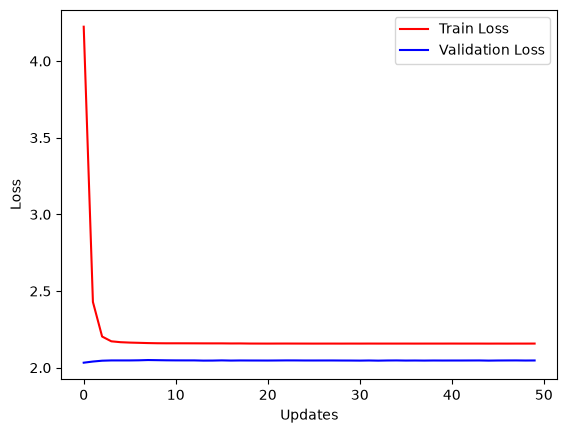

In [30]:
# setting hyperparameters and gettings epoch sizes
num_epochs = 50
num_samples_train = X_train_substrings.shape[0]
num_samples_valid = X_val_substrings.shape[0]
batch_size = 2048

# setting up lists for handling loss/accuracy
train_acc, train_loss = [], []
valid_acc, valid_loss = [], []
test_acc, test_loss = [], []
cur_loss = 0
losses = []
val_losses = []

train_data_loader = DataLoader(TensorDataset(X_train_substrings.long(), y_train_substrings),
                      batch_size=batch_size, shuffle=True)
val_data_loader   = DataLoader(TensorDataset(X_val_substrings.long(), y_val_substrings),
                      batch_size=batch_size)

for epoch in range(num_epochs):
    ## Train
    cur_loss, correct, n = 0.0, 0, 0
    net.train()
    for x_batch, y_batch in train_data_loader:
        optimizer.zero_grad()
        output = net(x_batch)
        
        # compute gradients given loss
        batch_loss = criterion(output, y_batch)
        
        # L1 regularization
        lambda_reg = 0.001
        l1_norm = sum(p.abs().sum() for p in net.parameters())
        batch_loss += lambda_reg * l1_norm
        
        # L2 regularization
        # lambda_reg = 0.001
        # l2_norm = sum(p.pow(2).sum() for p in net.parameters())
        # batch_loss += lambda_reg * l2_norm
        
        batch_loss.backward()
        optimizer.step()
        
        cur_loss += batch_loss.item() * len(y_batch)
        correct += (output.argmax(1) == y_batch).sum().item()
        n += len(y_batch)
        
    losses.append(cur_loss / n)
    train_acc_cur = correct / n if n > 0 else 0

    net.eval()
    
    ### Evaluate validation
    with torch.no_grad():
        v_cur_loss, v_correct, v_n = 0.0, 0, 0
        for x_batch, y_batch in val_data_loader:        
            output = net(x_batch)
            v_cur_loss += criterion(output, y_batch).item() * len(y_batch)
            v_correct += (output.argmax(1) == y_batch).sum().item()
            v_n += len(y_batch)
        val_losses.append(v_cur_loss / v_n)
        val_acc_cur = v_correct / v_n if v_n > 0 else 0
        
    train_acc.append(train_acc_cur)
    valid_acc.append(val_acc_cur)
    
    if epoch % 10 == 0:
        print("Epoch %2i : Train Loss %f , Train acc %f, Valid acc %f" % (
                epoch+1, losses[-1], train_acc_cur, val_acc_cur))

epoch = np.arange(len(train_acc))
plt.figure()
plt.plot(epoch, losses, 'r', epoch, val_losses, 'b')
plt.legend(['Train Loss','Validation Loss'])
plt.xlabel('Updates'), plt.ylabel('Loss')

In [31]:
# Save the net temporarily
torch.save(net.state_dict(), 'mlp_baseline.pth')

In [32]:
# Read the net back in
net = MLP_baseline(num_features, embedding_dim, num_hidden, num_classes)
net.load_state_dict(torch.load('mlp_baseline.pth'))

<All keys matched successfully>

# Generate sequences

In [35]:
num_seq = 100
seq_length = 129

sequences = []
sequences_numerical = []
temperature = 0.5 

net.eval()

for i in range(num_seq):
    # Generate a start sequence of length 3: <BOS>, start codon, and random amino acid
    random_sequence = [1, 13]
    random_sequence.append(np.random.randint(3, 22))  # Random amino acid index
    
    for _ in range(seq_length - 3):
        # Pass the current sequence through the model to get the next amino acid prediction
        x = torch.tensor([random_sequence[-3:]], dtype=torch.int)
        with torch.no_grad():
            probs = F.softmax(net(x) / temperature, dim=1)
        
        # Append the predicted amino acid to the sequence
        random_sequence.append(torch.multinomial(probs, 1).item())
    
    sequences.append(translate_generated_sequence(random_sequence, tokenizer=data_train))
    sequences_numerical.append(random_sequence)
    
# Save sequences to a csv file
output_file = '../results/sequences/generated_sequences.csv'
result_df = pd.DataFrame(sequences, columns=['sequence'])

result_df.to_csv(output_file, index=False)
    

print("Generated Sequences:")
for seq in sequences:
    print(seq)
    
# print("Generated Sequences (Numerical):")
# for seq in sequences_numerical:
#     print(seq)

Generated Sequences:
MSAGETVAPVRSMGFVTHTRLALAGAVISVSEVQAAVRLANSAGNPATTEIARVEGVSKEAEVEAEAIALANVELAVTTKASARKFVALKEATTKEAVSARIKSAVKKGFQAAVVLLTALSAGVVLLA
MCVKAVELAVLVVNVVEIVAEKGTTVGPKGLVAEAGGVVGLLAGAGDVAEAVRVTAVTRAAGLFKGFFVASEGRVETVAALGVSAESELVEGEYNSVASEARPISLVTLDAATEILVSERVDGFVAFA
MPAIAAVEVLQVTVGVAAVLAVVATGREAFAGVFRNGELPEEVTAAEARGAQEQKAVTLADVLKLVNVVDGAIGETTFEEKGGFDAVKAATGFGGDVEGAATKVNYSEKIASPAEVKKRGGAVLKREI
MGALGIFLFVSGRAEAGNVAGLRVAGTSVDIAGDVLDGERVNSEGLAEASVVAIMGFQTGLKVEKVFVTVIAAGAIDNRVQRVGRGMEEKASTYLVDEAGFVVAVLLEAVRLRDAAAEATPGFRLKFV
MSALLVRGQEVLRLLLEGIDAGVESKGASVTAIAAVIIIAVEVDAAAAAPDVKKALVGSRLKALVKLEAKASAEGAVGAVTALLAVGKPKGPLAEVKNTELLTLGGAANEARELGEAKKMDAVLRDGA
MVAAKAAALSELGVMADGVSGRVPTSVAKAGGVEGDLSTAQVKGVDGDAFKAVAETSGIPSAKDESLPADGSPALLNGEALEIDGIEADAVTEAAGAKEAGTLGSEVAGRPGSEASVELVVFGEFQLL
MTSNRHKAFTGFALSLAALEIVNVNAEAREANVSIGSKQQLKVKTTAELEIRTGRGEVRAALQAVFANAANVALADAIGFRDAAAKRLESVSDGGATARVVAAAAELVPLPNRTRARAELKKELAARG
MHLLEGEAAAEATDEGLLAAPSAEAEASANVPARVATAVVGVTDFELEAAKANENAEAPYAKIAIEKAGLVLARDL